<a href="https://colab.research.google.com/github/Us9r/association-rule-mining/blob/main/association_rule_rsud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.Import dan Load Dataset

In [1]:
import warnings

def custom_showwarning(*args, **kwargs):
    pass

warnings.showwarning = custom_showwarning
import re
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = 'https://raw.githubusercontent.com/Us9r/association-rule-mining/main/dataset_v2/Data%20RSUD%20Sekayu%20Revisi.csv'
df = pd.read_csv(url, sep=';')

## Exploratory Data Analysis (EDA)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 347 entries, 0 to 346
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Registration No        347 non-null    object 
 1   MRN                    347 non-null    object 
 2   Subjective             347 non-null    object 
 3   Objective              347 non-null    object 
 4   Assessment/ Diagnosis  347 non-null    object 
 5   Planning               346 non-null    object 
 6   Diagnosis Name         345 non-null    object 
 7   Unnamed: 7             0 non-null      float64
 8   Unnamed: 8             0 non-null      float64
dtypes: float64(2), object(7)
memory usage: 24.5+ KB


In [4]:
df.describe()

,Unnamed: 7,Unnamed: 8
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


In [5]:
df.head(4)

,Registration No,MRN,Subjective,Objective,Assessment/ Diagnosis,Planning,Diagnosis Name,Unnamed: 7,Unnamed: 8
0,Registration No,MRN,Subjective,Objective,Assessment/ Diagnosis,Planning,NaN,NaN,NaN
1,REG/0063,428660,Keluhan utama: gatal seluruh badan,Keadaan umum: Sakit ringan,Anemia hipokrom mikrositer,"evaluasi pengobatan Hb 7,9 -> rencana transfus...","D64.9 - Anaemia, unspecified",NaN,NaN
2,REG/0677,225601,"Keluhan utama: lemas seluruh badan, nyeri pada...",Keadaan umum: Sakit ringan,Diagnisa banding: hipokalemia DM tipe 2,evaluasi pengobatan,E10.9 - Insulin-dependent diabetes militus wit...,NaN,NaN
3,REG/0024,159401,Keluhan utama: pusing berkurang,Keadaan umum: Sakit ringan,HHD DM tipe 2,Evaluasi td dan bss,E10.9 - Insulin-dependent diabetes militus wit...,NaN,NaN


In [6]:
# Menghapus baris di mana isi 'Registration No' adalah kata 'Registration No'
df_clean = df[df['Registration No'] != 'Registration No'].copy()

#lihat cuplikan
df_clean.head()

,Registration No,MRN,Subjective,Objective,Assessment/ Diagnosis,Planning,Diagnosis Name,Unnamed: 7,Unnamed: 8
1,REG/0063,428660,Keluhan utama: gatal seluruh badan,Keadaan umum: Sakit ringan,Anemia hipokrom mikrositer,"evaluasi pengobatan Hb 7,9 -> rencana transfus...","D64.9 - Anaemia, unspecified",NaN,NaN
2,REG/0677,225601,"Keluhan utama: lemas seluruh badan, nyeri pada...",Keadaan umum: Sakit ringan,Diagnisa banding: hipokalemia DM tipe 2,evaluasi pengobatan,E10.9 - Insulin-dependent diabetes militus wit...,NaN,NaN
3,REG/0024,159401,Keluhan utama: pusing berkurang,Keadaan umum: Sakit ringan,HHD DM tipe 2,Evaluasi td dan bss,E10.9 - Insulin-dependent diabetes militus wit...,NaN,NaN
4,REG/0036,272790,"Keluhan utama: kaki sembap, BAK berbusa. Riway...",Keadaan umum: Sakit ringan,Sindrom nefrotik ICD 10.03 - Secondary Diagnos...,evaluasi lab,"N04.9 - Nephrotic syndrome, unspecified",NaN,NaN
5,REG/0037,370576,"Keluhan utama: batuk, Riwayat penyakit dahulu:...",Keadaan umum: Sakit ringan,Asma terkontrol derajat ringan ICD 10: 01 - Ma...,evaluasi faktor pencetus,"J45.9 - Asthma, unspecified",NaN,NaN


##Memilih fitur yang akan digunakan
(Feature selection)

*   Periksa nilai fitur Unnamed: 7 dan 8
*   Tidak ada nilai unique (tidak ada isi) di fitur 7 dan 8
*   Drop fitur yang tidak digunakan


In [7]:
print("Nilai unik Unnamed: 7:", df['Unnamed: 7'].unique())
print("Nilai unik Unnamed: 8:", df['Unnamed: 8'].unique())

Nilai unik Unnamed: 7: [nan]
Nilai unik Unnamed: 8: [nan]


In [8]:
# Menghapus kolom 'Subjective', 'Objective', 'Assessment/ Diagnosis', dan 'Planning'
df_clean = df_clean.drop(columns=['Subjective', 'Objective', 'Assessment/ Diagnosis', 'Planning','Unnamed: 7', 'Unnamed: 8'])

# Menampilkan beberapa baris pertama setelah kolom dihapus
df_clean.head(3)

,Registration No,MRN,Diagnosis Name
1,REG/0063,428660,"D64.9 - Anaemia, unspecified"
2,REG/0677,225601,E10.9 - Insulin-dependent diabetes militus wit...
3,REG/0024,159401,E10.9 - Insulin-dependent diabetes militus wit...


# 2.Data Cleaning
identifikasi missing values

In [9]:
missing_rows = df_clean[df_clean.isna().any(axis=1)]
print(f"Jumlah baris dengan missing value: {len(missing_rows)}")
display(missing_rows)

Jumlah baris dengan missing value: 1


,Registration No,MRN,Diagnosis Name
87,REG/01219,187298,NaN


drop baris yang memiliki missing value

In [10]:
df_clean = df_clean.dropna()

## Duplicates Values
Identifikasi fitur yang memiliki nilai duplikat berdasarkan

In [11]:
# Filter duplikat MRN lalu urutkan berdasarkan kolom MRN
duplicate_reg = df_clean[df_clean.duplicated(subset=['Registration No'], keep=False)].sort_values(by='Registration No')

In [12]:
duplicate_reg

,Registration No,MRN,Diagnosis Name
4,REG/0036,272790,"N04.9 - Nephrotic syndrome, unspecified"
230,REG/0036,272790,I11.9 - Hypertensive heart disease without (co...
231,REG/0037,244537,E10.9 - Insulin-dependent diabetes mellitus wi...
5,REG/0037,370576,"J45.9 - Asthma, unspecified"
235,REG/0058,316190,E10.9 - Insulin-dependent diabetes mellitus wi...
...,...,...,...
279,REG/0698,443969,K21.0 - Gastro-oesophageal reflux disease with...
225,REG/0733,205293,"E04.9 - Nontoxic goitre, unspecified"
185,REG/0733,322250,"K80.8 - Other cholelithiasis, I11.9 - Hyperten..."
255,REG/0767,360498,"E04.1 - Nontoxic single thyroid nodule, R59.9 ..."


### 96 baris duplikat berdasarkan Registration No terdeteksi

hal ini wajar terjadi karena pencatatan no registrasi reset berulang di awal atau akhir bulan

Lanjut identifikasi duplikat berdasarkan MRN

In [13]:
# Filter duplikat MRN lalu urutkan berdasarkan kolom MRN
duplicate_mrn = df_clean[df_clean.duplicated(subset=['MRN'], keep=False)].sort_values(by='MRN')

# Tampilkan seluruh baris tanpa dipotong/dibatasi tambahkan parameter
# pd.set_option('display.max_rows', None)
duplicate_mrn

,Registration No,MRN,Diagnosis Name
242,REG/0124,115306,"E05.9 - Thyrotoxicosis, unspecified"
26,REG/0157,115306,E10.5 - Insulin-dependent diabetes mellitus wi...
311,REG/0217,127380,E11.9 - Non-insulin-dependent diabetes mellitu...
61,REG/0492,127380,"I10 - Essential (primary) hypertension, R42 - ..."
342,REG/0713,127560,"E05.9 - Thyrotoxicosis, unspecified"
...,...,...,...
298,REG/0067,428660,"J45.9 - Asthma, unspecified, E11.9 - Non-insul..."
56,REG/0436,438491,E10.9 - Insulin-dependent diabetes mellitus wi...
344,REG/0446,438491,E11.9 - Non-insulin-dependent diabetes mellitu...
81,REG/0117,443697,I11.9 - Hypertensive heart disease without (co...


### 62 baris duplikat berdasarkan MRN terdeteksi
hal ini bisa terjadi karena
* Pasien datang berobat rutin
* Pasien datang dihari berbeda dengan gejala berbeda (2x)

data duplikat kembali diperiksa secara manual terlebih dahulu

In [14]:
# Mengekstrak dataframe duplicate_mrn ke file Excel
duplicate_mrn.to_excel('duplicate_mrn.xlsx', index=False)
print("File 'duplicate_mrn.xlsx' berhasil disimpan!")

File 'duplicate_mrn.xlsx' berhasil disimpan!


## Solusi Penanganan Duplikat MRN
Dalam analisis aturan asosiasi (*Association Rule Mining*), duplikasi `MRN` dengan nomor registrasi yang berbeda menunjukkan pasien yang melakukan kunjungan berulang.

Berikut adalah dua cara untuk menangani kondisi ini:

#### Opsi 1: Menggabungkan Diagnosis Berdasarkan MRN (Pendekatan Riwayat Pasien)
Semua diagnosis dari pasien (`MRN`) yang sama digabungkan menjadi satu baris transaksi tunggal.

In [15]:
# Opsi 1: Mengelompokkan berdasarkan MRN dan menggabungkan semua Diagnosis
df_by_patient = df_clean.groupby('MRN')['Diagnosis Name'].apply(lambda x: ', '.join(x.dropna().unique())).reset_index()

print("Ukuran data setelah penggabungan berdasarkan MRN:", df_by_patient.shape)
display(df_by_patient.head())

Ukuran data setelah penggabungan berdasarkan MRN: (314, 2)


,MRN,Diagnosis Name
0,100203,E11.9 - Non-insulin-dependent diabetes mellitu...
1,101807,N23 - Unspecified renal colic
2,102181,E05.0 - Thyrotoxicosis with diffuse goitre
3,107200,"I10 - Essential (primary) hypertension, J37.0 ..."
4,107719,"N30.9 - Cystitis, unspecified"


#### Opsi 2: Menghapus Duplikat secara keseluruhan
Jika setiap kunjungan (`Registration No`) adalah transaksi mandiri yang unik, kita tidak perlu menghapus duplikat `MRN` karena itu merepresentasikan kunjungan di waktu yang berbeda.

#### Dan kali ini Opsi 1 yang dipilih

In [16]:
df_by_patient

,MRN,Diagnosis Name
0,100203,E11.9 - Non-insulin-dependent diabetes mellitu...
1,101807,N23 - Unspecified renal colic
2,102181,E05.0 - Thyrotoxicosis with diffuse goitre
3,107200,"I10 - Essential (primary) hypertension, J37.0 ..."
4,107719,"N30.9 - Cystitis, unspecified"
...,...,...
309,447524,I11.9 - Hypertensive heart disease without (co...
310,447530,"E05.9 - Thyrotoxicosis, unspecified"
311,447544,E11.9 - Non-insulin-dependent diabetes mellitu...
312,474082,"R59.9 - Enlarged lymph nodes, unspecified, A18..."


In [17]:
# Mengekstrak dataframe df_by_patient ke file Excel
df_by_patient.to_excel('df_by_patient.xlsx', index=False)
print("File 'df_by_patient.xlsx' berhasil disimpan!")

File 'df_by_patient.xlsx' berhasil disimpan!


## Ekstrak kode ICD-10 dari fitur diagnosis name

In [18]:
# Fungsi revisi untuk mengekstrak hanya 3 karakter kode ICD-10 (contoh: E11, K30, I10)
def ekstrak_icd_3_karakter(text):
    if pd.isna(text):
        return ""
    # Pola regex untuk mendeteksi 3 karakter pertama ICD-10: Satu Huruf diikuti 2 Angka
    pattern = r'[A-Z]\d{2}'
    matches = re.findall(pattern, text)
    # Menggunakan list(dict.fromkeys(...)) untuk menjaga urutan unik jika ada kode duplikat yang terekstrak
    unique_matches = list(dict.fromkeys(matches))
    return ", ".join(unique_matches)

# Terapkan fungsi revisi ke df_clean dan df_by_patient
df_clean['ICD Code'] = df_clean['Diagnosis Name'].apply(ekstrak_icd_3_karakter)
df_by_patient['ICD Code'] = df_by_patient['Diagnosis Name'].apply(ekstrak_icd_3_karakter)

# Tampilkan hasil perubahan
print("Hasil ekstraksi 3 karakter ICD-10:")
display(df_by_patient[['Diagnosis Name', 'ICD Code']].head(10))

Hasil ekstraksi 3 karakter ICD-10:


,Diagnosis Name,ICD Code
0,E11.9 - Non-insulin-dependent diabetes mellitu...,"E11, K30"
1,N23 - Unspecified renal colic,N23
2,E05.0 - Thyrotoxicosis with diffuse goitre,E05
3,"I10 - Essential (primary) hypertension, J37.0 ...","I10, J37, J06"
4,"N30.9 - Cystitis, unspecified",N30
5,E05 - Thyrotoxicosis [hyperthyroidism],E05
6,"E05.9 - Thyrotoxicosis, unspecified",E05
7,"J40 - Bronchitis, not specified as acute or ch...","J40, J44"
8,E11.9 - Non-insulin-dependent diabetes mellitu...,"E11, K76"
9,E11.9 - Non-insulin-dependent diabetes mellitu...,"E11, I10"


In [19]:
df_by_patient

,MRN,Diagnosis Name,ICD Code
0,100203,E11.9 - Non-insulin-dependent diabetes mellitu...,"E11, K30"
1,101807,N23 - Unspecified renal colic,N23
2,102181,E05.0 - Thyrotoxicosis with diffuse goitre,E05
3,107200,"I10 - Essential (primary) hypertension, J37.0 ...","I10, J37, J06"
4,107719,"N30.9 - Cystitis, unspecified",N30
...,...,...,...
309,447524,I11.9 - Hypertensive heart disease without (co...,"I11, M19"
310,447530,"E05.9 - Thyrotoxicosis, unspecified",E05
311,447544,E11.9 - Non-insulin-dependent diabetes mellitu...,"E11, I11"
312,474082,"R59.9 - Enlarged lymph nodes, unspecified, A18...","R59, A18"


In [20]:
# Memeriksa baris dengan string kosong (jika ada yang gagal terekstrak)
empty_count = df_by_patient[df_by_patient['ICD Code'] == ""]

print(f"Jumlah baris gagal terekstrak: {len(empty_count)}")
display(empty_count)

Jumlah baris gagal terekstrak: 0


,MRN,Diagnosis Name,ICD Code


# 3.One-Hot Encoding

* Ubah dataframe jadi tipe data list
* Hapus spasi
* cek hasil

In [21]:
# 1. Ubah string 'E11.9, K30' menjadi list unik ['E11.9', 'K30']
transaksi = df_by_patient['ICD Code'].apply(
    lambda x: list(set(kode.strip() for kode in x.split(',')))
).tolist()

In [22]:
# 2. Lakukan One-Hot Encoding menggunakan TransactionEncoder
te = TransactionEncoder()
te_ary = te.fit(transaksi).transform(transaksi)
df_encoded = pd.DataFrame(te_ary, columns=te.columns_)

In [23]:
# Cek hasil matriks transaksi (314 pasien x jumlah kode ICD unik)
print("Ukuran matriks transaksi:", df_encoded.shape)
display(df_encoded.head())

Ukuran matriks transaksi: (314, 90)


,A01,A15,A16,A18,B18,B35,D56,D63,D64,E03,...,R10,R19,R31,R42,R51,R59,R73,R74,Z00,Z03
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# 4.FP-Growth Algorithm

In [24]:
# 1. Jalankan algoritma FP-Growth
# min_support=0.01 berarti muncul minimal pada 1% dari total pasien (~3 pasien)
frequent_itemsets = fpgrowth(df_encoded, min_support=0.01, use_colnames=True)

# Urutkan dari nilai support tertinggi
frequent_itemsets = frequent_itemsets.sort_values(by='support', ascending=False).reset_index(drop=True)

print(f"Total frequent itemsets ditemukan: {len(frequent_itemsets)}")
display(frequent_itemsets.head(15))

Total frequent itemsets ditemukan: 73


,support,itemsets
0,0.216561,(I11)
1,0.203822,(I10)
2,0.181529,(K30)
3,0.181529,(E11)
4,0.156051,(E05)
5,0.152866,(E10)
6,0.073248,(M19)
7,0.063694,"(I10, E11)"
8,0.057325,(K76)
9,0.057325,"(I11, K30)"


In [25]:
# 2. Ekstrak aturan asosiasi dari frequent itemsets
# min_threshold=0.5 berarti tingkat kepercayaan (confidence) minimal 50%
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

# Pilih kolom utama dan urutkan berdasarkan nilai Lift tertinggi
kolom_utama = ['antecedents', 'consequents', 'support', 'confidence', 'lift']
rules_clean = rules[kolom_utama].sort_values(by='lift', ascending=False).reset_index(drop=True)

# Rapikan tampilan frozenset menjadi teks kode ICD biasa
rules_clean['antecedents'] = rules_clean['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_clean['consequents'] = rules_clean['consequents'].apply(lambda x: ', '.join(list(x)))

print(f"Total aturan asosiasi terbentuk: {len(rules_clean)}")
display(rules_clean)

Total aturan asosiasi terbentuk: 12


,antecedents,consequents,support,confidence,lift
0,"I10, K76",N20,0.012739,0.800000,25.120000
1,G63,"I11, E10",0.015924,1.000000,19.625000
2,"I10, N20",K76,0.012739,1.000000,17.444444
3,N20,K76,0.019108,0.600000,10.466667
4,G63,E10,0.015924,1.000000,6.541667
5,"I11, G63",E10,0.015924,1.000000,6.541667
6,G63,I11,0.015924,1.000000,4.617647
7,"G63, E10",I11,0.015924,1.000000,4.617647
8,"N20, K76",I10,0.012739,0.666667,3.270833
9,I25,K30,0.012739,0.571429,3.147870


### Petakan kembali kode ke diagnosa nya

In [26]:
icd_map = {}
# Regex menangkap deskripsi secara utuh sampai sebelum kode ICD berikutnya atau akhir teks
pattern = re.compile(r'([A-Z]\d{2}(?:\.\d+)?)\s*[-*]\s*(.*?)(?=,?\s*[-+]?\(?[A-Z]\d{2}|$)')

for diag_text in df_by_patient['Diagnosis Name'].dropna():
    for full_code, desc in pattern.findall(str(diag_text)):
        code_3char = full_code[:3]
        if code_3char not in icd_map:
            # Bersihkan spasi, koma, atau kurung tutup sisa di ujung deskripsi
            clean_desc = desc.strip(' ,)')
            icd_map[code_3char] = f"{full_code} - {clean_desc}"

# Jalankan ulang pemetaan tabel
def terjemahkan_kode(kode_str):
    kode_list = [k.strip() for k in str(kode_str).split(',')]
    return ' + '.join([f"{k} ({icd_map.get(k, 'Tidak diketahui')})" for k in kode_list])

rules_readable = rules_clean.copy()
rules_readable['Antecedents (Jika)'] = rules_readable['antecedents'].apply(terjemahkan_kode)
rules_readable['Consequents (Maka)'] = rules_readable['consequents'].apply(terjemahkan_kode)

display(rules_readable[['Antecedents (Jika)', 'Consequents (Maka)', 'support', 'confidence', 'lift']])

,Antecedents (Jika),Consequents (Maka),support,confidence,lift
0,I10 (I10 - Essential (primary) hypertension) +...,N20 (N20.0 - Calculus of kidney),0.012739,0.800000,25.120000
1,G63 (G63.2 - Diabetic polyneuropathy),I11 (I11.9 - Hypertensive heart disease withou...,0.015924,1.000000,19.625000
2,I10 (I10 - Essential (primary) hypertension) +...,"K76 (K76.0 - Fatty (change of) liver, not else...",0.012739,1.000000,17.444444
3,N20 (N20.0 - Calculus of kidney),"K76 (K76.0 - Fatty (change of) liver, not else...",0.019108,0.600000,10.466667
4,G63 (G63.2 - Diabetic polyneuropathy),E10 (E10.5 - Insulin-dependent diabetes mellit...,0.015924,1.000000,6.541667
5,I11 (I11.9 - Hypertensive heart disease withou...,E10 (E10.5 - Insulin-dependent diabetes mellit...,0.015924,1.000000,6.541667
6,G63 (G63.2 - Diabetic polyneuropathy),I11 (I11.9 - Hypertensive heart disease withou...,0.015924,1.000000,4.617647
7,G63 (G63.2 - Diabetic polyneuropathy) + E10 (E...,I11 (I11.9 - Hypertensive heart disease withou...,0.015924,1.000000,4.617647
8,N20 (N20.0 - Calculus of kidney) + K76 (K76.0 ...,I10 (I10 - Essential (primary) hypertension),0.012739,0.666667,3.270833
9,I25 (I25.1 - Atherosclerotic heart disease),K30 (K30 - Dyspepsia),0.012739,0.571429,3.147870


# 5.Visualization

### Barchart

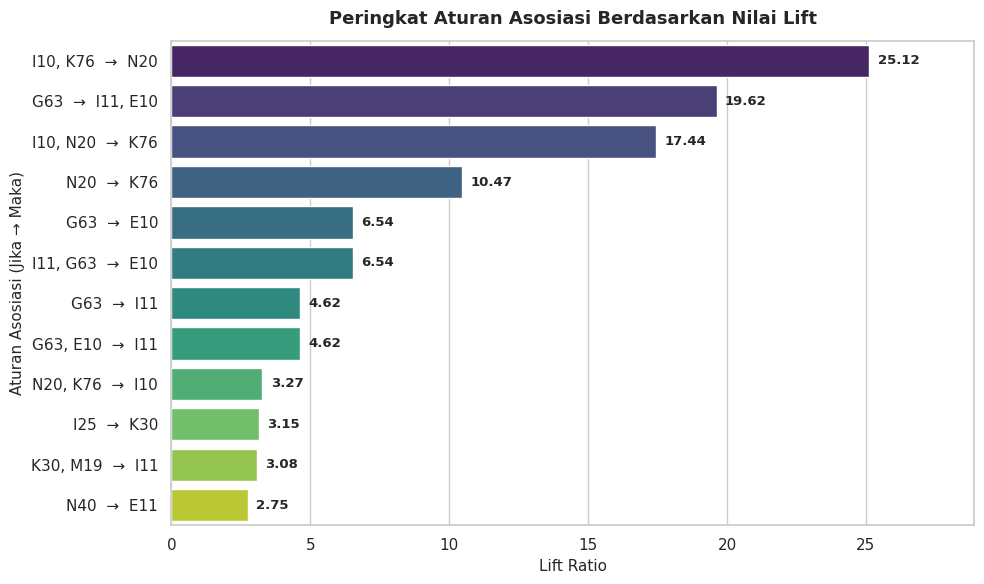

In [27]:
sns.set_theme(style="whitegrid")

rules_plot = rules_clean.copy()
rules_plot['Aturan'] = rules_plot['antecedents'] + '  →  ' + rules_plot['consequents']
rules_sorted = rules_plot.sort_values(by='lift', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=rules_sorted,
    x='lift',
    y='Aturan',
    palette='viridis',
    hue='Aturan',
    legend=False
)

plt.title('Peringkat Aturan Asosiasi Berdasarkan Nilai Lift', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Lift Ratio', fontsize=11)
plt.ylabel('Aturan Asosiasi (Jika → Maka)', fontsize=11)
plt.xlim(0, rules_sorted['lift'].max() * 1.15)

for index, value in enumerate(rules_sorted['lift']):
    plt.text(value + 0.3, index, f'{value:.2f}', va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.savefig('peringkat_lift_ratio.png', dpi=300, bbox_inches='tight')
plt.show()

### Scatterplot

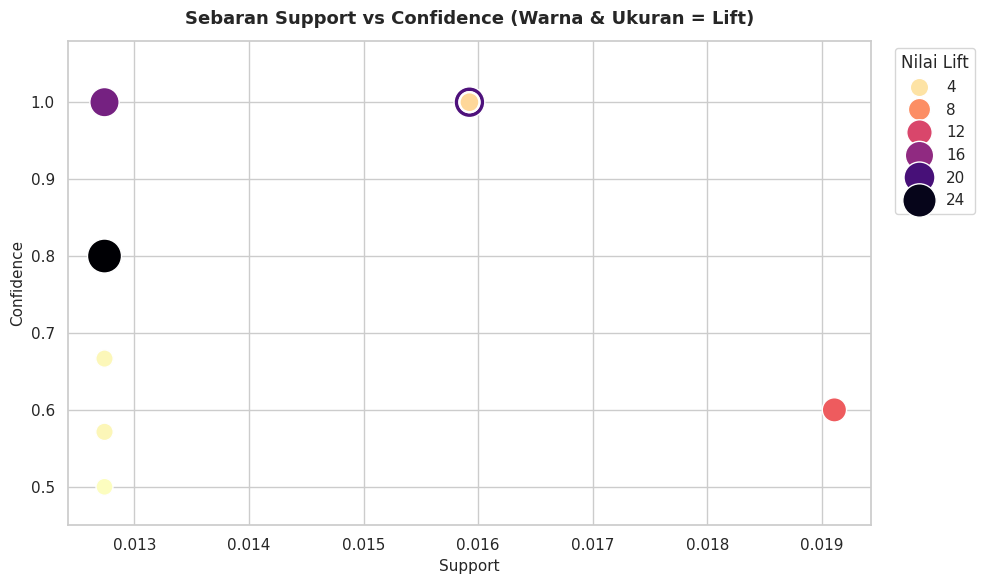

In [28]:
sns.set_theme(style="whitegrid")

rules_plot = rules_clean.copy()
rules_plot['Aturan'] = rules_plot['antecedents'] + '  →  ' + rules_plot['consequents']

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rules_plot,
    x='support',
    y='confidence',
    hue='lift',
    size='lift',
    sizes=(150, 600),
    palette='magma_r'
)

plt.title('Sebaran Support vs Confidence (Warna & Ukuran = Lift)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.ylim(0.45, 1.08)
plt.legend(title='Nilai Lift', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig('sebaran_support_vs_confidence.png', dpi=300, bbox_inches='tight')
plt.show()

## Heatmap

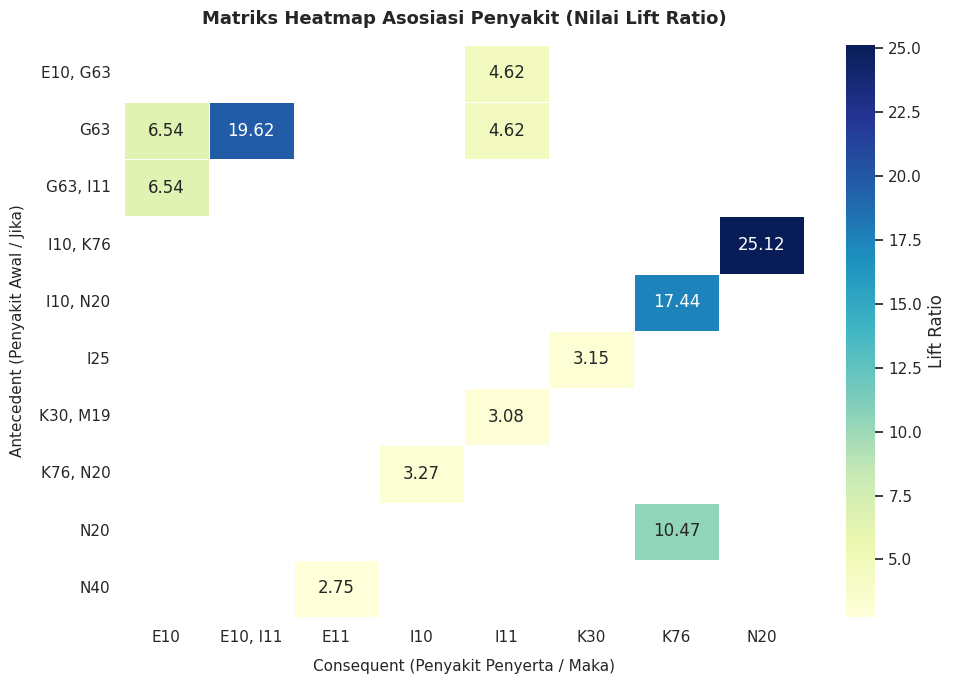

In [29]:
# 1. Menyiapkan DataFrame baru dari rules_clean
df_heatmap = rules_clean.copy()

# Memastikan antecedents dan consequents dalam format string terurut alfabetis
# (rules_clean di notebook Anda sudah didefinisikan sebagai string, namun kita pastikan kembali formatnya bersih)
def clean_rule_string(val):
    if isinstance(val, (set, frozenset)):
        return ', '.join(sorted(list(val)))
    elif isinstance(val, str):
        return ', '.join(sorted([x.strip() for x in val.split(',')]))
    return str(val)

df_heatmap['antecedents'] = df_heatmap['antecedents'].apply(clean_rule_string)
df_heatmap['consequents'] = df_heatmap['consequents'].apply(clean_rule_string)

# 2. Membuat Pivot Table dengan 'lift' sebagai nilainya
pivot_matrix = df_heatmap.pivot(index='antecedents', columns='consequents', values='lift')

# 3. Mengatur gaya visualisasi menggunakan Seaborn
sns.set_theme(style="white")
plt.figure(figsize=(10, 7))

# Membuat heatmap
sns.heatmap(
    pivot_matrix,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Lift Ratio'}
)

# 4. Memberikan judul dan label sumbu
plt.title('Matriks Heatmap Asosiasi Penyakit (Nilai Lift Ratio)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Consequent (Penyakit Penyerta / Maka)', fontsize=11, labelpad=10)
plt.ylabel('Antecedent (Penyakit Awal / Jika)', fontsize=11, labelpad=10)

# Menghindari label yang terpotong
plt.tight_layout()

# Menyimpan gambar
plt.savefig('heatmap_matriks_asosiasi.png', dpi=300, bbox_inches='tight')
plt.show()